# **Business Understanding**

**Description:**
A simple yet challenging project, to predict the housing price based on certain factors like house area, bedrooms, furnished, nearness to mainroad, etc. The dataset is small yet, it's complexity arises due to the fact that it has strong multicollinearity. Can you overcome these obstacles & build a decent predictive model?

**Acknowledgement:**
Harrison, D. and Rubinfeld, D.L. (1978) Hedonic prices and the demand for clean air. J. Environ. Economics and Management 5, 81–102.
Belsley D.A., Kuh, E. and Welsch, R.E. (1980) Regression Diagnostics. Identifying Influential Data and Sources of Collinearity. New York: Wiley.


**Sources:**
- [Dataset](https://www.kaggle.com/datasets/yasserh/housing-prices-dataset)

#### **Load Lbraries**

In [22]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

#### **Load Data**

In [23]:
df = pd.read_csv("data/Housing.csv")

# **Data Understanding**

- peak at your data
- Dimensions
- columns
- data types
- data quality: 
    - missing values
    - outliers
    - duplicates


In [24]:
df.head() # get top 5 elements of my data

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [25]:
df.tail() # last 5 elemtns of my data

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [26]:
rows, columns = df.shape 
output = f"{rows} records and {columns} features"
print(output)

545 records and 13 features


In [27]:
features =  df.columns # gives us our features/ columns
print(features)

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')


In [28]:
df.dtypes

price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [30]:
df.isna().sum()*100/len(df) # percentage missing values

price               0.0
area                0.0
bedrooms            0.0
bathrooms           0.0
stories             0.0
mainroad            0.0
guestroom           0.0
basement            0.0
hotwaterheating     0.0
airconditioning     0.0
parking             0.0
prefarea            0.0
furnishingstatus    0.0
dtype: float64

In [31]:
df.duplicated().sum()*100/len(df) # percentage duplicates  records

np.float64(0.0)

In [32]:
df.describe() # statistical summary of numerical features

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [33]:
df.describe(include="object") # statistical summary of non-numerical features

/tmp/ipykernel_16303/285175380.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object") # statistical summary of non-numerical features


,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


Histogram

In [38]:
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()

In [45]:
median_price

np.float64(4340000.0)

In [57]:
mode_price[0].item()

3500000

/tmp/ipykernel_16303/1781557353.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["price"], bins=10, color="orange")


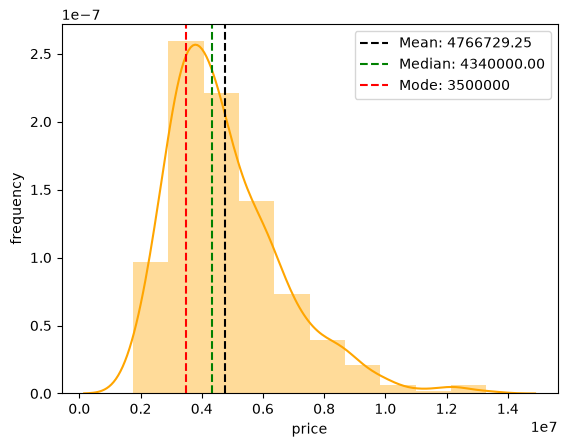

In [78]:
sns.distplot(df["price"], bins=10, color="orange")
#  MCTS 
plt.axvline(mean_price, color="black", linestyle="--", label=f"Mean: {mean_price:.2f}")
plt.axvline(median_price, color="green", linestyle="--", label=f"Median: {median_price:.2f}")
plt.axvline(mode_price[0], color="red", linestyle="--", label=f"Mode: {mode_price[0]}")

plt.xlabel("price")
plt.ylabel("frequency")
plt.legend()
plt.show()

/tmp/ipykernel_16303/2882977656.py:1: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["price"], vert=False)


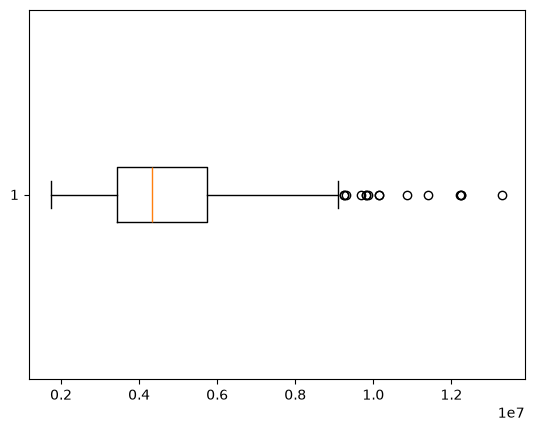

In [ ]:
sns.distplot(df["price"], bins=10, color="orange")
#  MCTS
plt.boxplot(df["price"], vert=False)
plt.axvline(mean_price, color="black", linestyle="--", label=f"Mean: {mean_price:.2f}")
plt.axvline(median_price, color="green", linestyle="--", label=f"Median: {median_price:.2f}")
plt.axvline(mode_price[0], color="red", linestyle="--", label=f"Mode: {mode_price[0]}")

plt.xlabel("price")
plt.ylabel("frequency")
plt.legend()
plt.show()

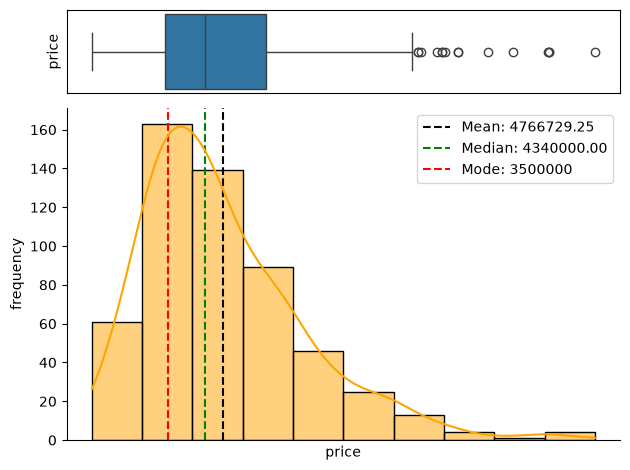

In [86]:
fig, (ax_box, ax_hist) = plt.subplots(
    2, sharex=True,
    gridspec_kw={"height_ratios": [1, 4]}
)

ax_hist.axvline(mean_price, color="black", linestyle="--", label=f"Mean: {mean_price:.2f}")
ax_hist.axvline(median_price, color="green", linestyle="--", label=f"Median: {median_price:.2f}")
ax_hist.axvline(mode_price[0], color="red", linestyle="--", label=f"Mode: {mode_price[0]}")

# Boxplot (horizontal, top)
sns.boxplot(df["price"], ax=ax_box, vert=False)
ax_box.set_yticks([])

# Histogram (bottom)
sns.histplot(df["price"], bins=10, color="orange", ax=ax_hist, kde=True)

sns.despine(ax=ax_hist)
plt.xlabel("price")
plt.ylabel("frequency")
plt.legend()
plt.tight_layout()
plt.show()

In [91]:
df.dtypes

price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object

In [ ]:
for feature in df.columns:
    if df[feature].dtype == 'str':
        print(feature)
    
    # print(df[feature].dtype)

mainroad
guestroom
basement
hotwaterheating
airconditioning
prefarea
furnishingstatus


In [105]:
def distribution(df, feature):
    
    mean_price = df[feature].mean()
    median_price = df[feature].median()
    mode_price = df[feature].mode()

    fig, (ax_box, ax_hist) = plt.subplots(
    2, sharex=True,
    gridspec_kw={"height_ratios": [1, 4]}
    )
    

    ax_hist.axvline(mean_price, color="black", linestyle="--", label=f"Mean: {mean_price:.2f}")
    ax_hist.axvline(median_price, color="green", linestyle="--", label=f"Median: {median_price:.2f}")
    ax_hist.axvline(mode_price[0], color="red", linestyle="--", label=f"Mode: {mode_price[0]}")

    # Boxplot (horizontal, top)
    sns.boxplot(df["price"], ax=ax_box, vert=False)
    ax_box.set_yticks([])

    # Histogram (bottom)
    sns.histplot(df["price"], bins=10, color="orange", ax=ax_hist, kde=True)

    sns.despine(ax=ax_hist)
    plt.xlabel("price")
    plt.title(f"{feature} data distribution")
    plt.ylabel("frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

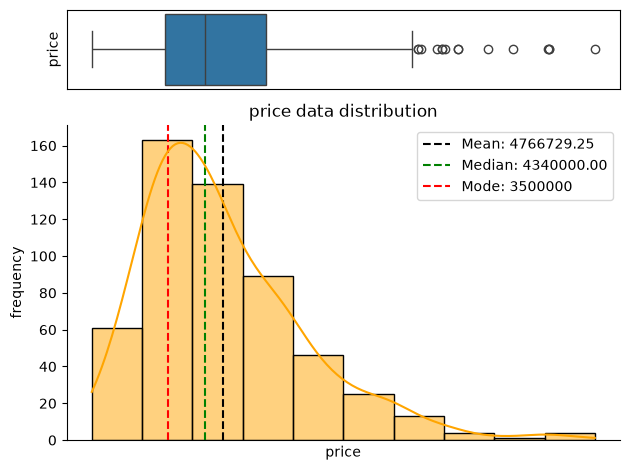

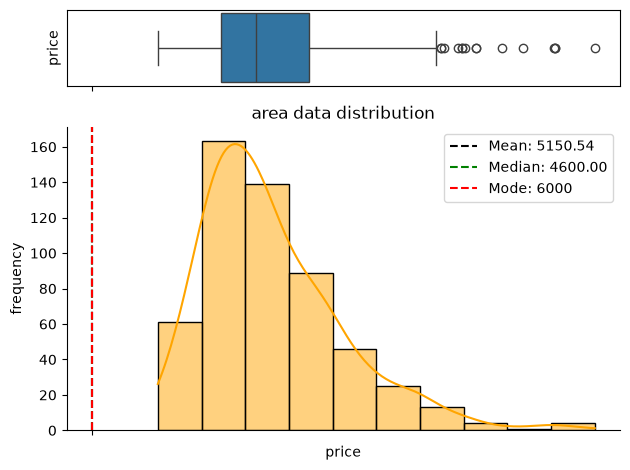

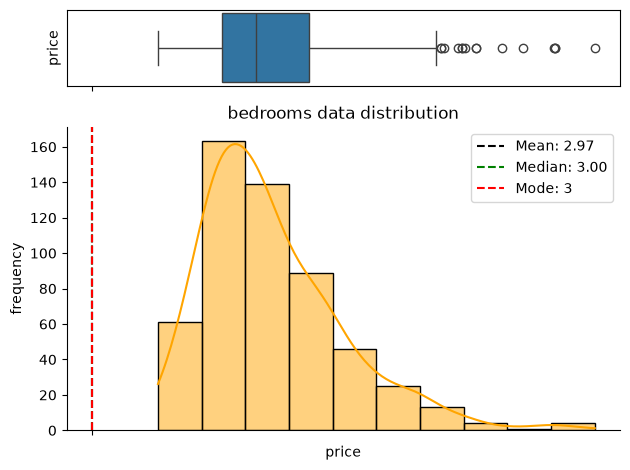

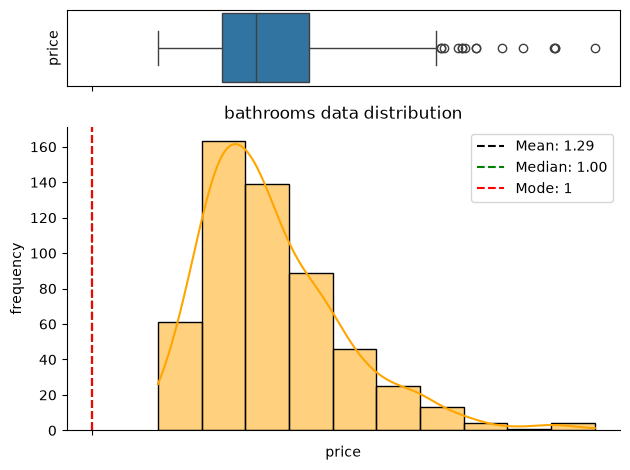

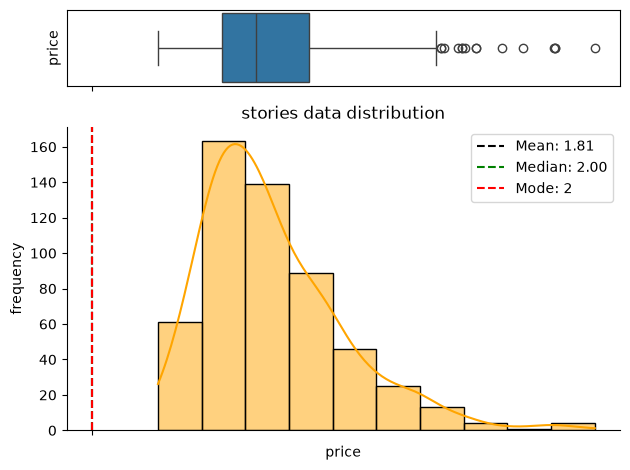

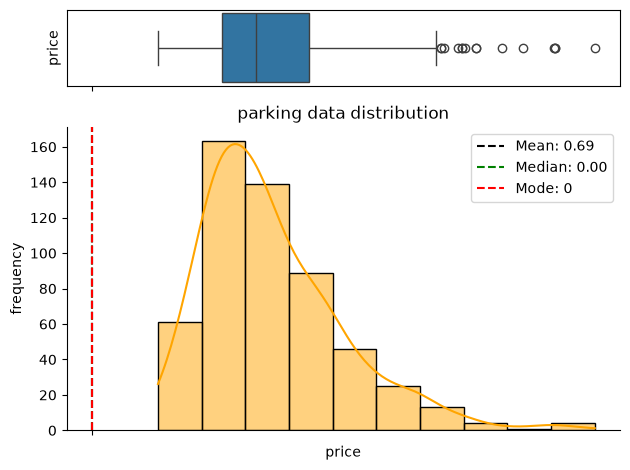

In [106]:
for feature in df.columns:
    if df[feature].dtype != 'str':
        distribution(df, feature)
        
    
    
    # print(df[feature].dtype)

# **Data Preparation**